# Miller et al. (2020) — Canagliflozin lifespan

[Miller et al., *JCI Insight* (2020)](https://doi.org/10.1172/jci.insight.140019) · [ITP data](https://phenome.jax.org/projects/ITP1)

UM-HET3 mice, Cana 180 ppm from month 7; sites: TJL, UM, UT. Reproduced: Figures 1, 3 and Tables 1, 2. Figures 2, 4 and supplemental measurements lack individual source data. Additional analyses appear after the paper sections.


## Inputs

```bash
uv add jupyter pandas openpyxl numpy scipy matplotlib lifelines statsmodels
```

`Lifespan_C2016.xlsx` and `BodyWeight_C2016.xlsx` (sheet `Data`) in the working directory. The weight file is derived from MPD JSON data.


In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from scipy.stats import fisher_exact, ttest_ind
from statsmodels.duration.survfunc import survdiff

LIFESPAN_FILE = Path("Lifespan_C2016.xlsx")
WEIGHT_FILE = Path("BodyWeight_C2016.xlsx")
GROUPS = ("Control", "Cana")
SITES = ("TJL", "UM", "UT")
SEXES = ("f", "m")

## 1. Survival data

Each row is one mouse: `age` is age at death or censoring; `dead=1` means death, `dead=0` means censored (removed from observation).


In [5]:
life = pd.read_excel(LIFESPAN_FILE)
survival = life.loc[
    life["group"].isin(GROUPS),
    ["site", "sex", "group", "age", "dead"],
].copy()

survival.groupby(["sex", "site", "group"]).agg(
    animals=("age", "size"),
    observed_deaths=("dead", "sum"),
)

animals  observed_deaths
sex site group                            
f   TJL  Cana          48               48
         Control       96               95
    UM   Cana          44               44
         Control       92               92
    UT   Cana          44               44
         Control      116              116
m   TJL  Cana          54               53
         Control      102               94
    UM   Cana          51               41
         Control      102               82
    UT   Cana          51               51
         Control       99               99

## 2. Figure 1 — Kaplan–Meier curves

$$
\hat S(t)=\prod_{t_i\leq t}\left(1-\frac{d_i}{n_i}\right)
$$

$d_i$: deaths at age $t_i$; $n_i$: mice at risk. Dots mark **every death** (tied events overlap). Blue Control is layered above orange Cana.


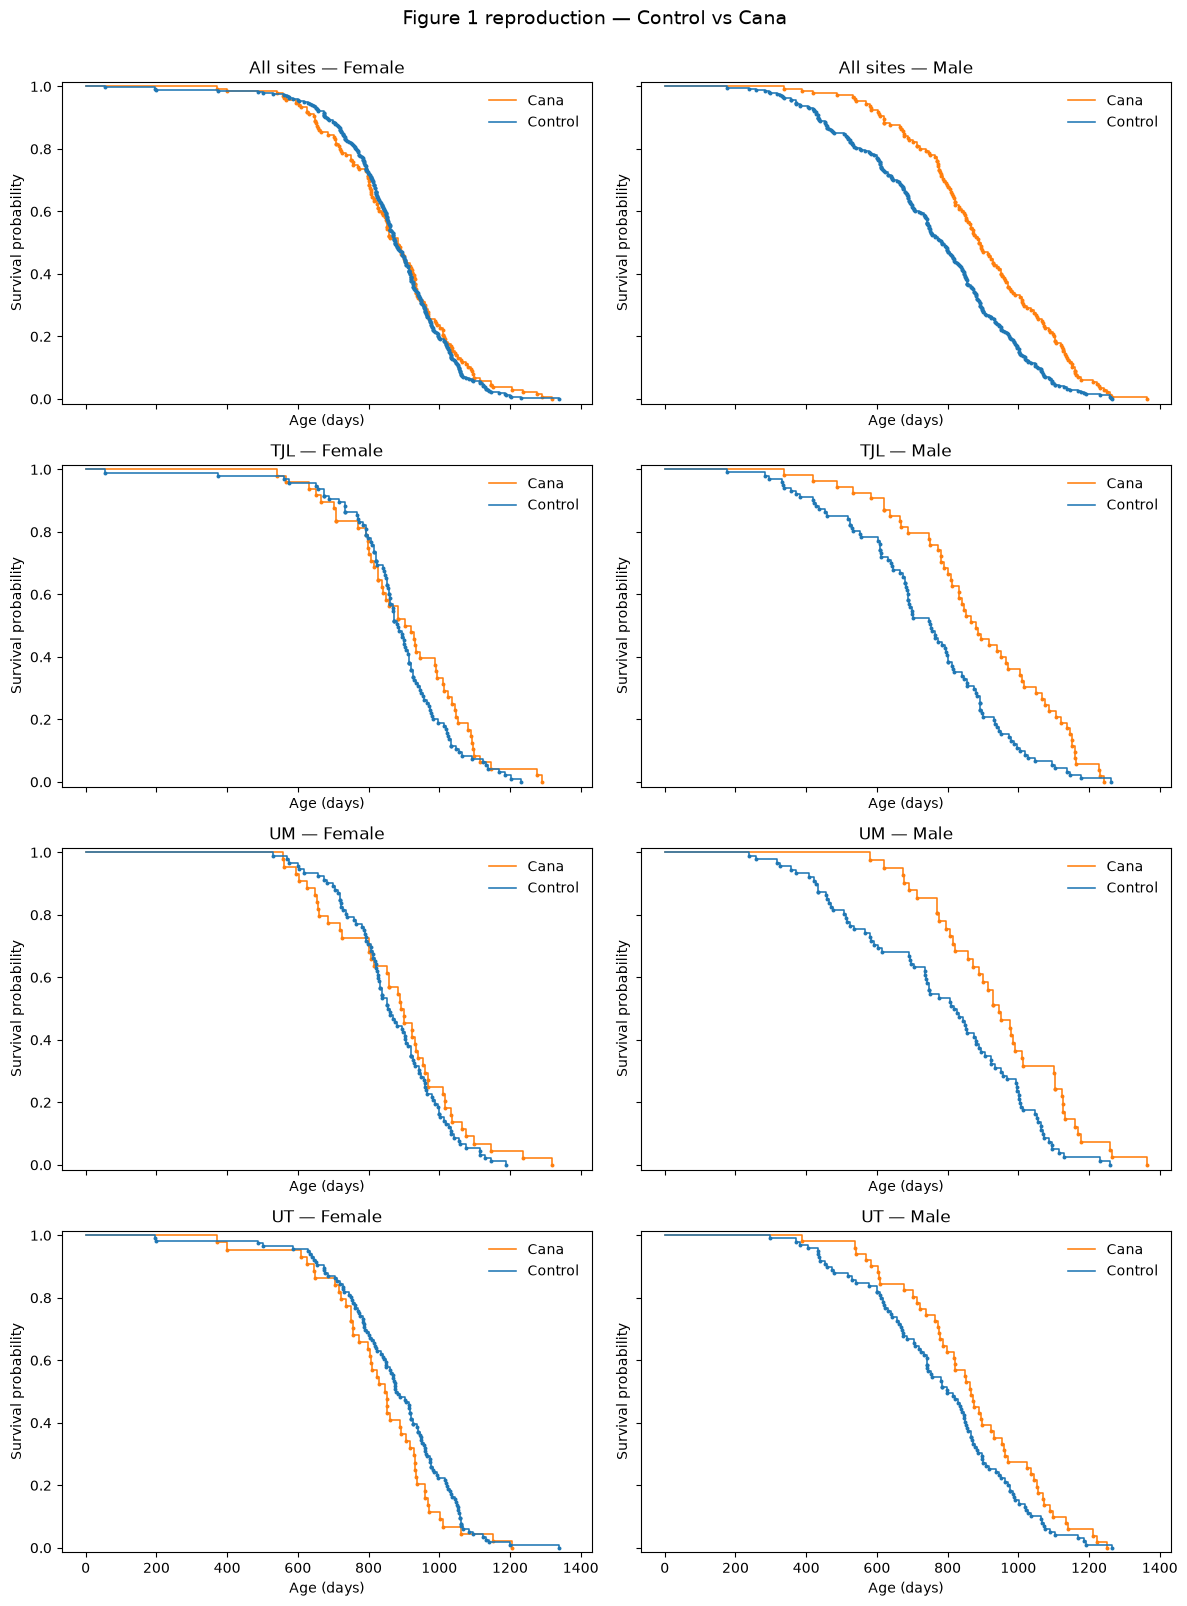

In [6]:
def draw_km_group(data, group, ax):
    """Kaplan–Meier curve with a marker for each observed death."""
    mouse_rows = data[data["group"] == group]
    fit = KaplanMeierFitter().fit(
        mouse_rows["age"],
        event_observed=mouse_rows["dead"],
        label=group,
    )

    color = "tab:blue" if group == "Control" else "tab:orange"
    z = 4 if group == "Control" else 2

    curve = fit.survival_function_.iloc[:, 0]
    ax.step(
        curve.index.to_numpy(), curve.to_numpy(),
        where="post", label=group, color=color,
        linewidth=1.15, zorder=z,
    )

    ages = mouse_rows.loc[mouse_rows["dead"].eq(1), "age"]
    heights = fit.survival_function_at_times(ages).to_numpy()
    ax.scatter(
        ages, heights, s=8, marker="o", color=color,
        zorder=z + 0.4, linewidths=0,
    )
    return fit


def draw_km_panel(data, ax, title):
    draw_km_group(data, "Cana", ax)
    draw_km_group(data, "Control", ax)
    ax.set(title=title, xlabel="Age (days)", ylabel="Survival probability")
    ax.set_ylim(-0.015, 1.015)
    ax.legend(frameon=False)


fig, axes = plt.subplots(4, 2, figsize=(12, 16), sharex=True, sharey=True)

for col, sex in enumerate(SEXES):
    sex_label = "Female" if sex == "f" else "Male"
    draw_km_panel(
        survival[survival["sex"] == sex],
        axes[0, col], f"All sites — {sex_label}",
    )
    for row, site in enumerate(SITES, start=1):
        subset = survival[
            (survival["sex"] == sex) & (survival["site"] == site)
        ]
        draw_km_panel(subset, axes[row, col], f"{site} — {sex_label}")

fig.suptitle("Figure 1 reproduction — Control vs Cana", y=1.001, fontsize=14)
plt.tight_layout()
plt.show()

## 3. Table 1 — lifespan and log-rank

Median and 90th-percentile ages use **observed deaths only**, excluding technical removals. Kaplan–Meier and log-rank analyses retain censored records. Pooled log-rank tests are **stratified by site**; site-specific tests are unstratified. Published percentile conventions may differ from NumPy interpolation.


In [7]:
def death_age_quantiles(data):
    ages = data.loc[data["dead"].eq(1), "age"].to_numpy()
    return float(np.median(ages)), float(np.percentile(ages, 90))


def logrank_p(data, pooled):
    statistic, p_value = survdiff(
        time=data["age"],
        status=data["dead"],
        group=data["group"],
        strata=data["site"] if pooled else None,
    )
    return float(statistic), float(p_value)


lifespan_rows = []
for sex in ("m", "f"):
    subset_sex = survival[survival["sex"] == sex]
    for site in ("Pool", *SITES):
        subset = (
            subset_sex if site == "Pool"
            else subset_sex[subset_sex["site"] == site]
        )
        control = subset[subset["group"] == "Control"]
        cana = subset[subset["group"] == "Cana"]

        median_c, p90_c = death_age_quantiles(control)
        median_t, p90_t = death_age_quantiles(cana)
        chi2, p = logrank_p(subset, pooled=(site == "Pool"))

        lifespan_rows.append({
            "sex": sex, "site": site,
            "n_control": len(control), "n_cana": len(cana),
            "median_control": median_c, "median_cana": median_t,
            "median_change_pct": 100 * (median_t / median_c - 1),
            "p90_control": p90_c, "p90_cana": p90_t,
            "p90_change_pct": 100 * (p90_t / p90_c - 1),
            "logrank_chi2": chi2, "logrank_p": p,
        })

lifespan_table = pd.DataFrame(lifespan_rows)
lifespan_table.round(3)

,sex,site,n_control,n_cana,median_control,median_cana,median_change_pct,p90_control,p90_cana,p90_change_pct,logrank_chi2,logrank_p
0,m,Pool,303,156,782.0,888.0,13.555,1053.8,1156.6,9.755,25.083,0.000
1,m,TJL,102,54,749.0,880.0,17.490,1002.0,1157.8,15.549,12.181,0.000
2,m,UM,102,51,814.0,946.0,16.216,1070.4,1170.0,9.305,11.425,0.001
3,m,UT,99,51,799.0,866.0,8.385,1040.8,1099.0,5.592,3.527,0.060
4,f,Pool,304,136,875.0,883.0,0.914,1055.0,1085.0,2.844,0.430,0.512
5,f,TJL,96,48,883.0,911.5,3.228,1053.0,1095.6,4.046,1.856,0.173
6,f,UM,92,44,858.0,896.5,4.487,1033.8,1072.4,3.734,1.253,0.263
7,f,UT,116,44,881.5,849.0,-3.687,1058.0,993.1,-6.134,2.159,0.142


## 4. Wang–Allison test

For each `sex × site`, the **pooled Control + Cana** Kaplan–Meier curve determines the age at which survival reaches 10%. At that cutoff, compare mice surviving to the age against observed earlier deaths via Fisher's exact test; earlier censorings are excluded. Pooled results sum site-specific counts.


In [8]:
def wang_allison_counts(data):
    # One KM curve from the two treatments COMBINED establishes the threshold.
    combined = KaplanMeierFitter().fit(data["age"], data["dead"])
    curve = combined.survival_function_.iloc[:, 0]

    cutoff = float(curve.index[curve.to_numpy() <= 0.10][0])

    rows = []
    for group in GROUPS:
        mice = data[data["group"] == group]

        alive = int(mice["age"].ge(cutoff).sum())
        died_earlier = int(
            (mice["age"].lt(cutoff) & mice["dead"].eq(1)).sum()
        )
        # Early censorings are deliberately absent from either count.
        rows.append({
            "group": group, "threshold_age": cutoff,
            "alive": alive, "dead": died_earlier,
        })
    return pd.DataFrame(rows)


wa_counts = pd.concat(
    [
        wang_allison_counts(
            survival[
                (survival["sex"] == sex)
                & (survival["site"] == site)
            ]
        ).assign(sex=sex, site=site)
        for sex in ("m", "f")
        for site in SITES
    ],
    ignore_index=True,
)
wa_counts

,group,threshold_age,alive,dead,sex,site
0,Control,1122.0,4,90,m,TJL
1,Cana,1122.0,11,42,m,TJL
2,Control,1123.0,3,79,m,UM
3,Cana,1123.0,10,31,m,UM
4,Control,1073.0,8,91,m,UT
5,Cana,1073.0,7,44,m,UT
6,Control,1092.0,8,87,f,TJL
7,Cana,1092.0,7,41,f,TJL
8,Control,1055.0,8,84,f,UM
9,Cana,1055.0,6,38,f,UM


In [9]:
wa_rows = []
for sex in ("m", "f"):
    sex_counts = wa_counts[wa_counts["sex"] == sex]
    for site in ("Pool", *SITES):
        counts = (
            sex_counts if site == "Pool"
            else sex_counts[sex_counts["site"] == site]
        )
        contingency = (
            counts.groupby("group")[["alive", "dead"]]
            .sum()
            .reindex(GROUPS)
        )
        odds_ratio, p_value = fisher_exact(
            contingency.to_numpy(), alternative="two-sided"
        )
        wa_rows.append({
            "sex": sex, "site": site,
            "wa_odds_control_over_cana": odds_ratio,
            "wa_p": p_value,
            "control_alive": int(contingency.loc["Control", "alive"]),
            "cana_alive": int(contingency.loc["Cana", "alive"]),
        })

wa_table = pd.DataFrame(wa_rows)
wa_table.round(5)

,sex,site,wa_odds_control_over_cana,wa_p,control_alive,cana_alive
0,m,Pool,0.24107,0.00003,15,28
1,m,TJL,0.16970,0.00309,4,11
2,m,UM,0.11772,0.00090,3,10
3,m,UT,0.55259,0.38869,8,7
4,f,Pool,0.79380,0.49852,29,16
5,f,TJL,0.53859,0.26253,8,7
6,f,UM,0.60317,0.38023,8,6
7,f,UT,1.72492,0.55976,13,3


## 5. Table 1 — calculated vs published

Published values are separate reference columns. Differences remain visible. Published male pooled P values of `<0.0001` are stored as `0.0001` thresholds, not exact values.


In [10]:
published_table1 = pd.DataFrame([
    # sex site n_control n_cana median_control median_cana p90_control p90_cana
    ("m", "Pool",303,156,787,897,1047,1143,14,9, 0.0001,0.0001),
    ("m", "TJL", 102, 54,749,880,1005,1159,17,15,0.001,0.003),
    ("m", "UM",  102, 51,814,946,1071,1170,16,9, 0.001,0.001),
    ("m", "UT",   99, 51,799,866,1064,1099,8, 3,  0.060,0.39),
    ("f", "Pool",304,136,874,886,1050,1059,1, 1,  0.512,0.50),
    ("f", "TJL",  96, 48,883,912,1057,1097,3, 4,  0.173,0.26),
    ("f", "UM",   92, 44,858,897,1034,1076,4, 4,  0.263,0.38),
    ("f", "UT",  116, 44,882,849,1058,1003,-4,-5, 0.142,0.56),
], columns=[
    "sex", "site", "n_control_pub", "n_cana_pub",
    "median_control_pub", "median_cana_pub",
    "p90_control_pub", "p90_cana_pub",
    "median_change_pct_pub", "p90_change_pct_pub",
    "logrank_p_pub", "wa_p_pub",
])

calculated_table1 = lifespan_table.merge(
    wa_table[["sex", "site", "wa_p"]], on=["sex", "site"]
)
comparison = calculated_table1.merge(
    published_table1, on=["sex", "site"], validate="one_to_one"
)

for name in ("n_control", "n_cana", "median_control", "median_cana",
             "p90_control", "p90_cana", "median_change_pct", "p90_change_pct"):
    comparison[name + "_difference"] = (
        comparison[name] - comparison[name + "_pub"]
    )

comparison[[
    "sex", "site", "n_control", "n_cana",
    "median_control", "median_control_pub", "median_cana", "median_cana_pub",
    "p90_control", "p90_control_pub", "p90_cana", "p90_cana_pub",
    "logrank_p", "logrank_p_pub", "wa_p", "wa_p_pub",
]].round(4)

,sex,site,n_control,n_cana,median_control,median_control_pub,median_cana,median_cana_pub,p90_control,p90_control_pub,p90_cana,p90_cana_pub,logrank_p,logrank_p_pub,wa_p,wa_p_pub
0,m,Pool,303,156,782.0,787,888.0,897,1053.8,1047,1156.6,1143,0.0000,0.0001,0.0000,0.0001
1,m,TJL,102,54,749.0,749,880.0,880,1002.0,1005,1157.8,1159,0.0005,0.0010,0.0031,0.0030
2,m,UM,102,51,814.0,814,946.0,946,1070.4,1071,1170.0,1170,0.0007,0.0010,0.0009,0.0010
3,m,UT,99,51,799.0,799,866.0,866,1040.8,1064,1099.0,1099,0.0604,0.0600,0.3887,0.3900
4,f,Pool,304,136,875.0,874,883.0,886,1055.0,1050,1085.0,1059,0.5120,0.5120,0.4985,0.5000
5,f,TJL,96,48,883.0,883,911.5,912,1053.0,1057,1095.6,1097,0.1730,0.1730,0.2625,0.2600
6,f,UM,92,44,858.0,858,896.5,897,1033.8,1034,1072.4,1076,0.2630,0.2630,0.3802,0.3800
7,f,UT,116,44,881.5,882,849.0,849,1058.0,1058,993.1,1003,0.1418,0.1420,0.5598,0.5600


## 6. Figure 2 — drug concentrations (published only)

Plasma Cana at 22 months, mean ± SEM: **female 13.2 ± 0.9 μg/mL (n=5)**; **male 3.6 ± 0.6 μg/mL (n=8)**. Female exposure was higher despite no lifespan benefit. Individual plasma/brain/kidney measurements are unavailable; plots cannot be reconstructed. [Paper](https://insight.jci.org/articles/view/140019).


## 7. Figure 3 — body weight

Weights at 6, 12, 18 and 24 months; treatment starts at month 7. Mean ± SEM of measured, living mice at each age:

$$
\mathrm{SEM}=\frac{s}{\sqrt{n}}
$$

Two-sided equal-variance Student t-tests compare Control and Cana separately for each sex and age, pooling sites.


In [11]:
weights_raw = pd.read_excel(WEIGHT_FILE, sheet_name="Data")
weights = weights_raw.loc[
    weights_raw["group"].isin(GROUPS),
    ["site", "sex", "animal_id", "group", "age_months", "body_weight_g"],
].copy()

weight_summary = (
    weights.groupby(["sex", "group", "age_months"])
    .agg(
        n=("body_weight_g", "count"),
        mean_g=("body_weight_g", "mean"),
        sem_g=("body_weight_g", "sem"),
    )
    .reset_index()
)
weight_summary.round(2)

,sex,group,age_months,n,mean_g,sem_g
0,f,Cana,6,136,34.04,0.60
1,f,Cana,12,136,34.10,0.52
2,f,Cana,18,133,36.98,0.61
3,f,Cana,24,107,37.14,0.65
4,f,Control,6,303,33.83,0.37
5,f,Control,12,301,41.19,0.47
6,f,Control,18,297,45.52,0.55
7,f,Control,24,255,44.65,0.61
8,m,Cana,6,151,41.81,0.45
9,m,Cana,12,141,43.69,0.52


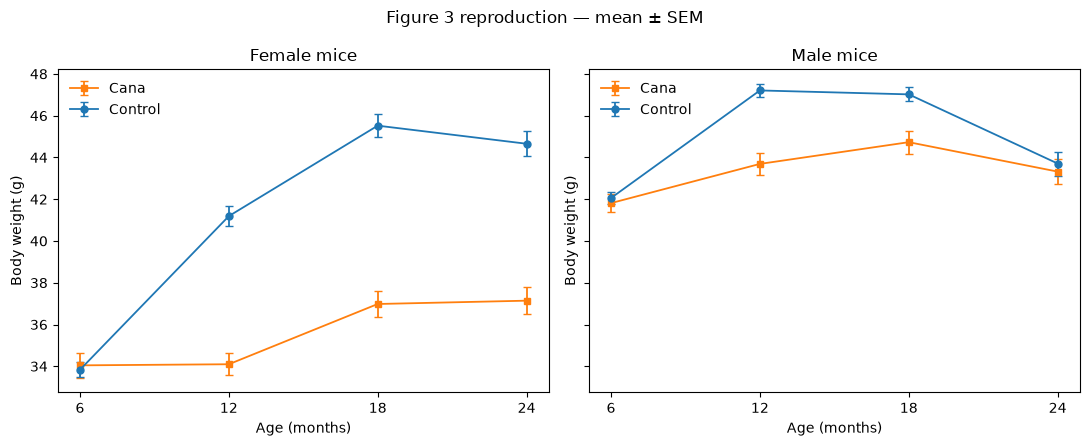

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, sex in zip(axes, SEXES):
    for group, color, marker in [
        ("Cana", "tab:orange", "s"),
        ("Control", "tab:blue", "o"),
    ]:
        x = weight_summary[
            (weight_summary["sex"] == sex)
            & (weight_summary["group"] == group)
        ].sort_values("age_months")
        ax.errorbar(
            x["age_months"], x["mean_g"], yerr=x["sem_g"],
            label=group, color=color, marker=marker,
            linewidth=1.3, markersize=5, capsize=3,
        )
    ax.set(
        title="Female mice" if sex == "f" else "Male mice",
        xlabel="Age (months)", ylabel="Body weight (g)",
        xticks=[6, 12, 18, 24],
    )
    ax.legend(frameon=False)

fig.suptitle("Figure 3 reproduction — mean ± SEM")
plt.tight_layout()
plt.show()

### Figure 3 — tests

Student's two-sided t-test (`equal_var=True`) at each sex × age. Published significant differences: females at 12, 18, 24 months; males at 12, 18 months.


In [13]:
weight_rows = []
for (sex, age), group_data in weights.groupby(["sex", "age_months"]):
    c = group_data.loc[
        group_data["group"] == "Control", "body_weight_g"
    ].dropna()
    t = group_data.loc[
        group_data["group"] == "Cana", "body_weight_g"
    ].dropna()

    test = ttest_ind(c, t, equal_var=True, alternative="two-sided")
    weight_rows.append({
        "sex": sex, "age_months": age,
        "n_control": len(c), "n_cana": len(t),
        "control_mean_g": c.mean(), "cana_mean_g": t.mean(),
        "change_pct": (t.mean() / c.mean() - 1) * 100,
        "t_statistic": float(test.statistic),
        "p_value": float(test.pvalue),
    })

weight_tests = pd.DataFrame(weight_rows)
weight_tests.round(5)

,sex,age_months,n_control,n_cana,control_mean_g,cana_mean_g,change_pct,t_statistic,p_value
0,f,6,303,136,33.83267,34.04412,0.62497,-0.31242,0.75487
1,f,12,301,136,41.18937,34.09706,-17.21879,9.00916,0.00000
2,f,18,297,133,45.52088,36.98195,-18.75825,9.35739,0.00000
3,f,24,255,107,44.65490,37.14112,-16.82633,7.27512,0.00000
4,m,6,286,151,42.05594,41.81258,-0.57866,0.46804,0.63999
5,m,12,268,141,47.20713,43.68936,-7.45177,6.17859,0.00000
6,m,18,220,137,47.01955,44.72993,-4.86950,3.77165,0.00019
7,m,24,162,116,43.70741,43.32069,-0.88479,0.46103,0.64514


## 8. HbA1c (published only)

Two-way ANOVA (sex × treatment): no treatment effect, significant sex effect. Means: male Control **3.8%**, Cana **3.7%**; female Control **3.5%**, Cana **3.5%**. Individual observations unavailable.


## 9. Figure 4 — metabolic outcomes (published only)

Separate 20–22-month subcohort: NMR body composition, fasting glucose and glucose tolerance. Reported in females: **~18% lower body mass**, **41% lower fat mass**; glucose tolerance improved in both sexes. Individual measurements unavailable.


## 10. Table 2 — pathology

Blinded pathology of **120 mice** (60 Control, 60 Cana). Published cause-of-death counts support category-wise Fisher exact tests; individual pathology records are unavailable.


In [14]:
pathology = pd.DataFrame({
    "cause": [
        "Hematopoietic neoplasia",
        "Hemangiosarcoma",
        "Liver neoplasia",
        "Lung carcinoma",
        "Neoplastic, other",
        "Atrial thrombosis",
        "Non-neoplastic, other",
        "Multiple or unknown",
        "Autolysis",
    ],
    "Cana": [18, 2, 3, 2, 9, 5, 6, 10, 5],
    "Control": [16, 3, 4, 5, 8, 2, 6, 11, 5],
})
pathology["Total"] = pathology["Control"] + pathology["Cana"]
pathology

,cause,Cana,Control,Total
0,Hematopoietic neoplasia,18,16,34
1,Hemangiosarcoma,2,3,5
2,Liver neoplasia,3,4,7
3,Lung carcinoma,2,5,7
4,"Neoplastic, other",9,8,17
5,Atrial thrombosis,5,2,7
6,"Non-neoplastic, other",6,6,12
7,Multiple or unknown,10,11,21
8,Autolysis,5,5,10


In [15]:
pathology_rows = []
for row in pathology.itertuples(index=False):
    table = np.array([
        [row.Control, 60 - row.Control],
        [row.Cana, 60 - row.Cana],
    ])
    odds_ratio, p_value = fisher_exact(table, alternative="two-sided")
    pathology_rows.append({
        "cause": row.cause, "Control": row.Control,
        "Cana": row.Cana, "odds_ratio": odds_ratio,
        "fisher_p": p_value,
    })

pathology_tests = pd.DataFrame(pathology_rows)
pathology_tests.round(4)

,cause,Control,Cana,odds_ratio,fisher_p
0,Hematopoietic neoplasia,16,18,0.8485,0.8397
1,Hemangiosarcoma,3,2,1.5263,1.0000
2,Liver neoplasia,4,3,1.3571,1.0000
3,Lung carcinoma,5,2,2.6364,0.4390
4,"Neoplastic, other",8,9,0.8718,1.0000
5,Atrial thrombosis,2,5,0.3793,0.4390
6,"Non-neoplastic, other",6,6,1.0000,1.0000
7,Multiple or unknown,11,10,1.1224,1.0000
8,Autolysis,5,5,1.0000,1.0000


### Pathology results

Hematopoietic neoplasia: **16/60 Control**, **18/60 Cana**. No significant differences by individual cause-of-death category. Neoplastic deaths among evaluable mice: **36/44 Control**, **34/45 Cana** (excludes ambiguous/autolyzed cases).
